### 1. Import das bibliotecas e definição da função de leitura

In [1]:
import requests
import pandas as pd

def read_ckan_sql(resource_id):
    url = "https://dados.uffs.edu.br/api/3/action/datastore_search_sql"

    limit = 1000
    offset = 0
    all_records = []

    while True:
        sql = f'''
        SELECT *
        FROM "{resource_id}"
        LIMIT {limit}
        OFFSET {offset}
        '''

        response = requests.get(url, params={"sql": sql})
        data = response.json()

        records = data["result"]["records"]

        if not records:
            break

        all_records.extend(records)
        offset += limit

        print(f"Baixados: {offset}")

    df = pd.DataFrame(all_records)
    return df

### 2. Passa o id dos dados pra função de leitura, e transforma o resultado em um dataframe pandas

In [3]:
df_pesquisa = read_ckan_sql("0dd4a7f8-0558-4be1-afa5-9837c73b2390")
print("Número de registros:", len(df_pesquisa))

Baixados: 1000
Baixados: 2000
Baixados: 3000
Baixados: 4000
Baixados: 5000
Baixados: 6000
Número de registros: 5296


### 3. Mostra os 5 primeiros registros

In [4]:
df_pesquisa.head()

,_id,_full_text,projeto_registro,projeto_titulo,data_inicio,data_fim,quant_coordenadores,coordenadores,nome_campus,desc_area_cnpq,...,resumo,modalidade,situacao_projeto,grupo_estudos_relacionado,envolve_animais,envolve_humanos,envolve_ogm,envolve_ppi,envolve_inovacao_tecnologica,data_atualizacao
0,1,'-01':25 '-04':352 '-06':353 '-08':27 '-09':24...,PES-2026-161,O uso de Textos de Divulgação Científica na Fo...,2026-09-01,2027-08-31,1,JUDITE SCHERER WENZEL,Cerro Largo,MÉTODOS E TÉCNICAS DE ENSINO,...,O presente projeto de pesquisa visa mapear em ...,SUB_PROJETO,PROPOSTA_AVALIACAO,Grupo de Estudos e Pesquisa em Ensino de Ciênc...,NÃO,NÃO,NÃO,NÃO,NÃO,2026-04-06T02:30:14.796090
1,2,'-04':616 '-06':617 '-09':24 '-10':21 '-160':3...,PES-2026-160,Produção Sustentável em Agroecossistemas no Su...,2026-10-26,2029-09-30,1,LEANDRO GALON,Erechim,MANEJO E TRATOS CULTURAIS,...,TÍTULO DO PROJETO: Produção Sustentável em Agr...,EDITAL_EXTERNO,PROPOSTA_AVALIACAO,Manejo Sustentável dos Sistemas Agrícolas - MASSA,NÃO,NÃO,NÃO,NÃO,NÃO,2026-04-06T02:30:14.796090
2,3,"'-01':22 '-03':24 '-04':21,454 '-06':455 '-159...",PES-2026-159,Proteína alternativa e bioinsumos: Insetos e d...,2026-04-01,2029-03-30,1,VANIA ZANELLA PINTO,Laranjeiras do Sul,"QUÍMICA, FÍSICA, FÍSICO-QUÍM. BIOQ. DOS ALI. M...",...,Pretendemos contribuir na elaboração e coorden...,EDITAL_EXTERNO,PROPOSTA_AVALIACAO,"Produção, transformação e armazenamento de ali...",NÃO,NÃO,NÃO,NÃO,NÃO,2026-04-06T02:30:14.796090
3,4,'-01':18 '-04':352 '-06':353 '-08':20 '-09':17...,PES-2026-158,Interceptação da água da chuva em uma parcela ...,2026-09-01,2027-08-31,1,FERNANDO GRISON,Chapecó,HIDROLOGIA,...,Os estudos hidrológicos em campo são essenciai...,SUB_PROJETO,PROPOSTA_AVALIACAO,Grupo de Pesquisa em Geotecnia e Recursos Hídr...,NÃO,NÃO,NÃO,NÃO,NÃO,2026-04-06T02:30:14.796090
4,5,'-01':12 '-04':516 '-06':517 '-08':14 '-09':11...,PES-2026-157,IA Gen em Letras 2026-2027,2026-09-01,2027-08-31,1,MARCUS VINICIUS LIESSEM FONTANA,Cerro Largo,LINGUÍSTICA APLICADA,...,A escrita constitui um dos pilares da vida aca...,SUB_PROJETO,PROPOSTA_AVALIACAO,POLIFONIA - Grupo de Pesquisas em Políticas Li...,NÃO,SIM,NÃO,NÃO,NÃO,2026-04-06T02:30:14.796090


### 4. Leitura do dicionário de dados do arquivo

In [5]:
df_dicionario_dados = read_ckan_sql("36d8b909-43de-4d3d-85be-894cc3daf608")
print("Número de registros:", len(df_dicionario_dados))

Baixados: 1000
Número de registros: 19


### 5. Mostra os registros

In [6]:
df_dicionario_dados

,_id,_full_text,coluna,tipo,rotulo,descricao
0,1,'ano':20 'cul/ens/ext/pes':19 'exceçã':31 'for...,projeto_registro,text,Nº Registro,Número de Registro do projeto no sistema Prism...
1,2,"'projet':1,7 'text':3 'titul':2 'títul':4,5",projeto_titulo,text,Título,Título do Projeto.
2,3,"'comec':12 'dat':1,3,4,7 'inic':17 'inici':2 '...",data_inicio,date,Data de Início,Data em que o projeto começou ou em pretende s...
3,4,"'dat':1,3,4,7 'encerr':19 'fim':2 'prev':17 'p...",data_fim,date,Data de Término,Data em que o projeto terminou ou em que se pr...
4,5,"'cooorden':6 'coorden':2,9,18 'integ':3 'men':...",quant_coordenadores,integer,Quantidade de Cooordenadores,Quantidade de coordenadores do projeto. Todo p...
5,6,"'coorden':1,3,8 'nom':4 'pont':13 'projet':10 ...",coordenadores,text,Coordenadores,"Nome de todos os coordenadores do projeto, sep..."
6,7,"'camp':16 'campus':2,4,5 'criaçã':8,26 'envolv...",nome_campus,text,Campus,Campus responsável pela criação do projeto. Um...
7,8,"'are':2 'cnpq':3,7,16 'conhec':10 'desc':1 'gr...",desc_area_cnpq,text,Grande Área CNPq,Área de conhecimento do projeto em relação ao ...
8,9,"'chav':2,6,9 'palavr':1,5,8 'palavras-chav':4,...",palavras_chave,text,Palavras-chave,Palavras-chave relacionadas ao projeto.
9,10,'descriçã':4 'objet':16 'projet':11 'qua':13 '...,resumo,text,Resumo,Descrição sucinta sobre o que trata o projeto ...


### Funções úteis

In [7]:
# 1. Função para formatar o número no padrão moeda do Brasil
from pandas.io.formats.style import Styler
def formatar_moeda_br(valor):
    if pd.isna(valor):
        return "R$ 0,00"
    
    # Formata com 2 casas decimais no padrão americano (ex: 1,234,567.89)
    valor_str = f"{valor:,.2f}"
    
    # Troca a vírgula por um 'X' temporário, o ponto por vírgula, e o 'X' por ponto
    valor_br = valor_str.replace(",", "X").replace(".", ",").replace("X", ".")
    
    return f"R$ {valor_br}"

## Análises iniciais

C:\Users\marco\AppData\Local\Temp\ipykernel_11940\3083878248.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  barras = sns.barplot(x=area_cnpq_counts.values, y=labels_quebradas, palette='cubehelix')


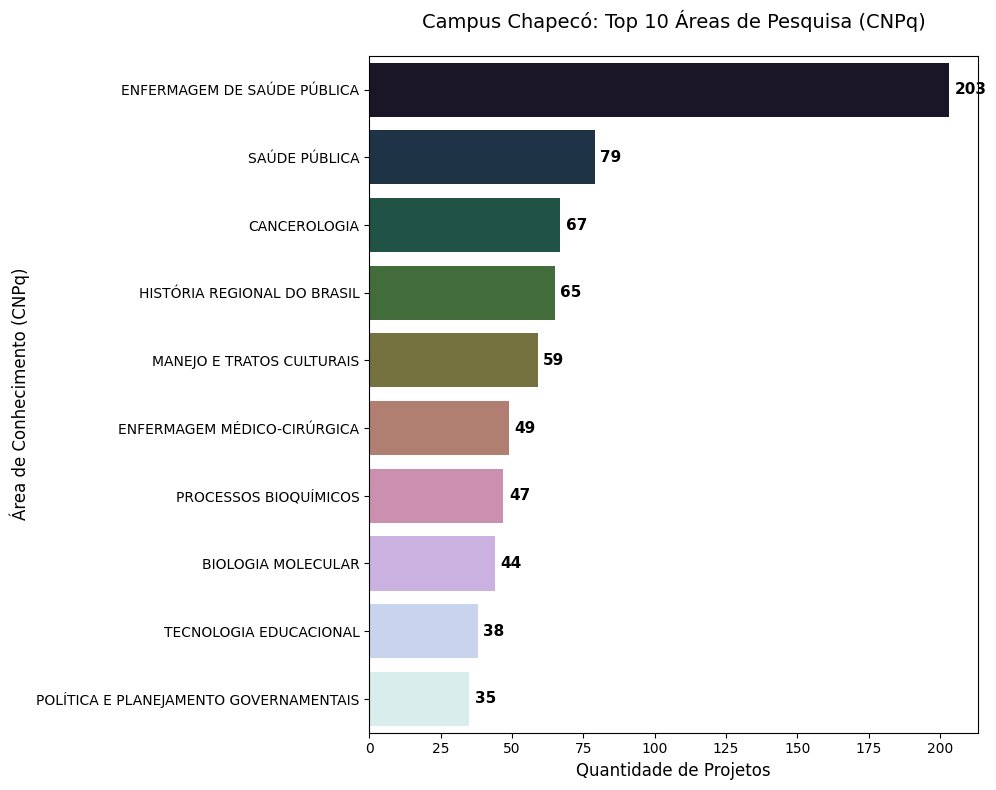

C:\Users\marco\AppData\Local\Temp\ipykernel_11940\3083878248.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_indicadores, x='Quantidade', y='Indicador', palette='Spectral')


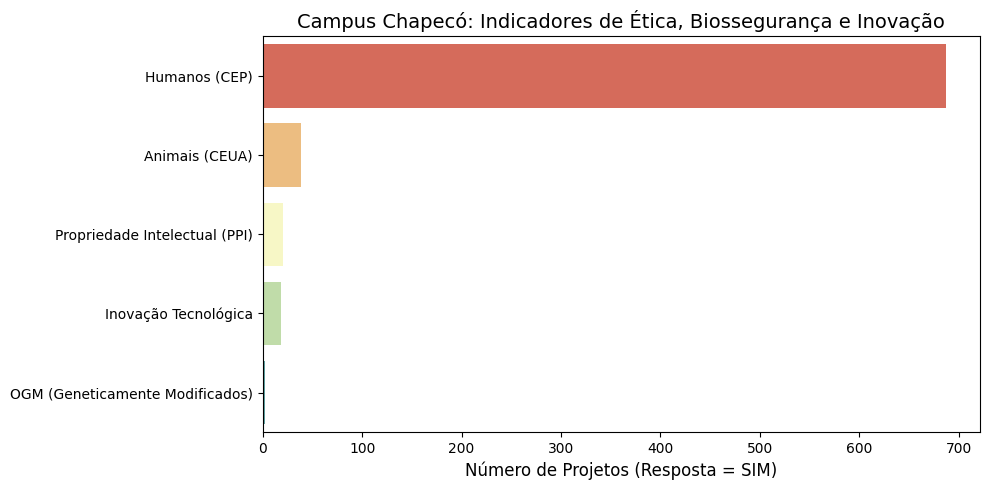

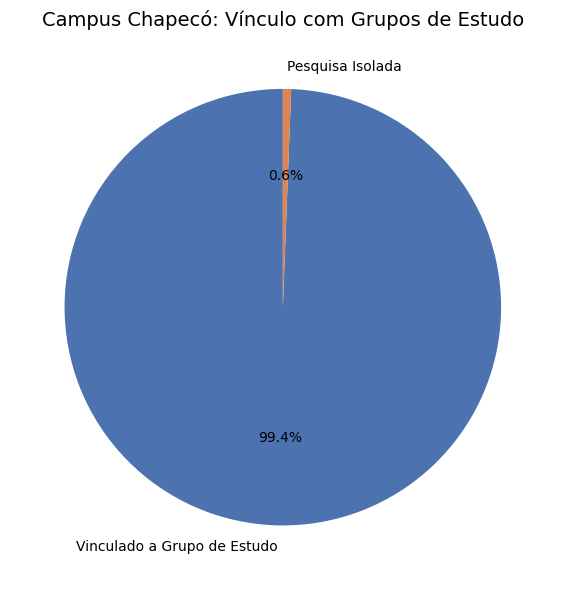

C:\Users\marco\AppData\Local\Temp\ipykernel_11940\3083878248.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_pesquisadores.values, y=top_pesquisadores.index, palette='rocket')


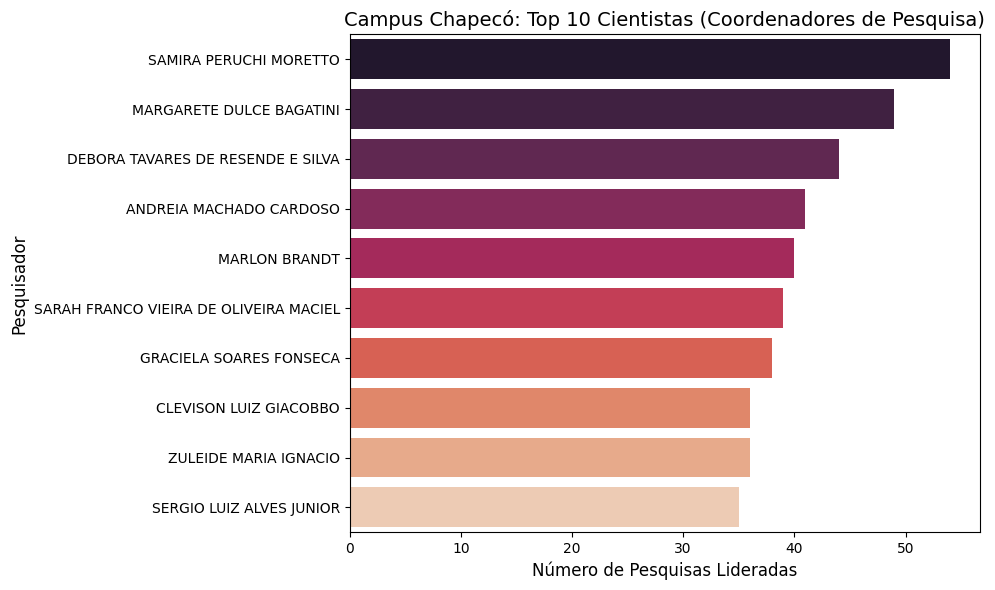

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import textwrap

# 0. A Mágica do Escopo (Filtrando apenas Chapecó)
# Assumindo que seu DataFrame original chama df_projetos_pesquisa
df_pesquisa_chapeco = df_pesquisa[df_pesquisa['nome_campus'] == 'Chapecó'].copy()

# ---------------------------------------------------------
# ANÁLISE 1: O Perfil Científico (Área CNPq)
# ---------------------------------------------------------
# 1. Pegar apenas o Top 10 para evitar poluição visual
top_n = 10
area_cnpq_counts = df_pesquisa_chapeco['desc_area_cnpq'].value_counts().head(top_n)

# 2. Quebrar os nomes muito grandes em até 40 caracteres por linha
labels_quebradas = [textwrap.fill(str(texto), width=40) for texto in area_cnpq_counts.index]

# 3. Aumentei a altura da figura (de 6 para 8) para dar "respiro" entre as barras
plt.figure(figsize=(10, 8)) 

# Criar o gráfico usando as labels quebradas
barras = sns.barplot(x=area_cnpq_counts.values, y=labels_quebradas, palette='cubehelix')

plt.title(f'Campus Chapecó: Top {top_n} Áreas de Pesquisa (CNPq)', fontsize=14, pad=20)
plt.xlabel('Quantidade de Projetos', fontsize=12)
plt.ylabel('Área de Conhecimento (CNPq)', fontsize=12)

# BÔNUS: Adicionar o número exato na ponta de cada barra!
for i, valor in enumerate(area_cnpq_counts.values):
    plt.text(valor + 2, i, str(valor), va='center', fontsize=11, color='black', fontweight='bold')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# ANÁLISE 2: Inovação e Indicadores de Compliance (Envolve X?)
# ---------------------------------------------------------
# Preparando os dados de "Envolvimento" para um gráfico de barras comparativo
indicadores = {
    'Humanos (CEP)': df_pesquisa_chapeco['envolve_humanos'].str.upper().eq('SIM').sum(),
    'Animais (CEUA)': df_pesquisa_chapeco['envolve_animais'].str.upper().eq('SIM').sum(),
    'Inovação Tecnológica': df_pesquisa_chapeco['envolve_inovacao_tecnologica'].str.upper().eq('SIM').sum(),
    'Propriedade Intelectual (PPI)': df_pesquisa_chapeco['envolve_ppi'].str.upper().eq('SIM').sum(),
    'OGM (Geneticamente Modificados)': df_pesquisa_chapeco['envolve_ogm'].str.upper().eq('SIM').sum()
}

df_indicadores = pd.DataFrame(list(indicadores.items()), columns=['Indicador', 'Quantidade'])
df_indicadores = df_indicadores.sort_values(by='Quantidade', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_indicadores, x='Quantidade', y='Indicador', palette='Spectral')
plt.title('Campus Chapecó: Indicadores de Ética, Biossegurança e Inovação', fontsize=14)
plt.xlabel('Número de Projetos (Resposta = SIM)', fontsize=12)
plt.ylabel('')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# ANÁLISE 3: Grupos de Estudo
# ---------------------------------------------------------
# Porcentagem de pesquisas atreladas a Grupos de Estudo vs Pesquisas Isoladas
com_grupo = df_pesquisa_chapeco['grupo_estudos_relacionado'].notna().sum()
sem_grupo = df_pesquisa_chapeco['grupo_estudos_relacionado'].isna().sum()

plt.figure(figsize=(6, 6))
plt.pie([com_grupo, sem_grupo], labels=['Vinculado a Grupo de Estudo', 'Pesquisa Isolada'], 
        autopct='%1.1f%%', colors=['#4c72b0', '#dd8452'], startangle=90)
plt.title('Campus Chapecó: Vínculo com Grupos de Estudo', fontsize=14)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# ANÁLISE 4: Top Pesquisadores (Coordenadores)
# ---------------------------------------------------------
coord_pesq_series = df_pesquisa_chapeco['coordenadores'].dropna().str.split(';').explode().str.strip()
top_pesquisadores = coord_pesq_series.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_pesquisadores.values, y=top_pesquisadores.index, palette='rocket')
plt.title('Campus Chapecó: Top 10 Cientistas (Coordenadores de Pesquisa)', fontsize=14)
plt.xlabel('Número de Pesquisas Lideradas', fontsize=12)
plt.ylabel('Pesquisador', fontsize=12)
plt.tight_layout()
plt.show()